In [1]:
from transformers import AutoTokenizer
import torch
import os
import pandas as pd
import numpy as np
import pickle
import glob
import matplotlib.pyplot as plt
from scipy import stats
import sys
sys.path.append('..')
from utils import calculate_cross_entropy,normalize_entropy,model_to_path_dict

In [ ]:
save_dir = '../../generated'
model_name = 'Llama3-8b-instruct' #'Llama3-8b' # 
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
model_initial_char = model_to_path_dict[model_name]['initial_char']
test_ce_kl_dir = os.path.join(save_dir,model_save_dir_name,'test_ce_kl')
test_files = glob.glob(os.path.join(test_ce_kl_dir,'*.txt'))
test_files.sort()

In [3]:
tokenizer = AutoTokenizer.from_pretrained(model_to_path_dict[model_name]['hf_name'])

I like to eat pizza. I like to eat hamburgers. I like to eat peaches. I like to eat onions. I like to eat soup. I like to eat bananas. I like to eat eat
I like to eat pizza. I like to eat hamburgers. I like to eat peaches. I like to eat onions. I like to eat soup. I like to eat bananas. I like to eat rocks
i like to eat pizza i like to eat hamburgers i like to eat peaches i like to eat onions i like to eat soup i like to eat bananas i like to eat eat



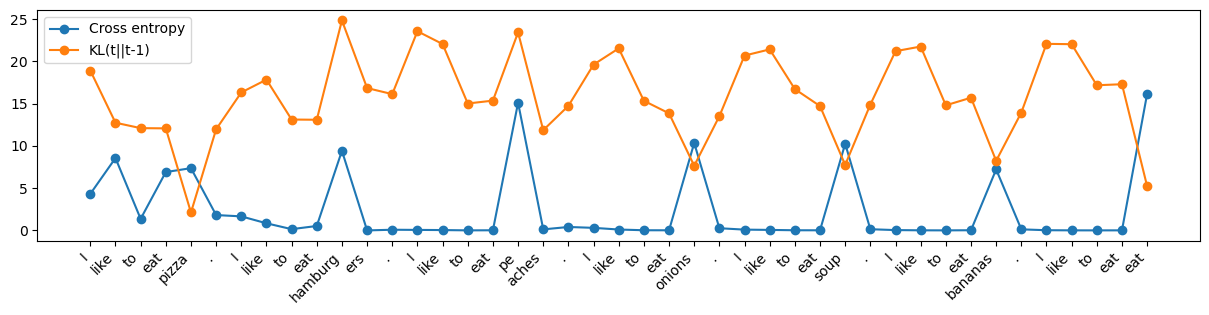

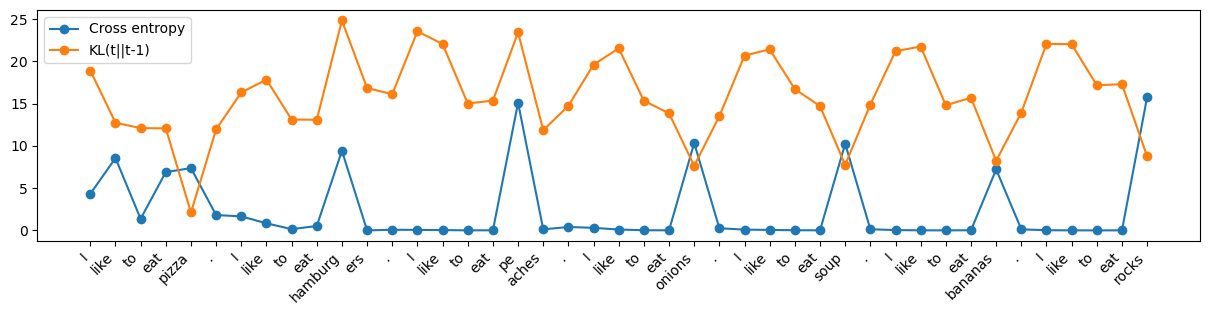

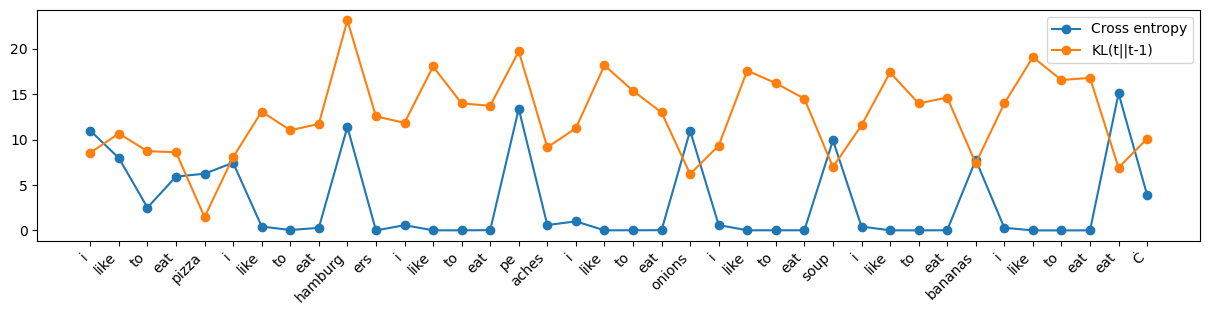

In [4]:
# Note: here KL(t||t-1) is KL (t predicting t+1 || t-1 predicting t)
# so the first value is KL (token 0 predicting token 1 || BOS predicting token 0) 
# the last value is KL (token t predicting nonexistent next token || token t-1 predicting token t)

for txt_file in test_files:
    file_stem = os.path.split(txt_file)[-1][:-4]
    output_dir = os.path.join(test_ce_kl_dir,file_stem)
    with open(txt_file,'r') as f:
        txt = f.read()
    print(txt)
    with open(os.path.join(output_dir,'cross_entropy.pkl'),'rb') as f:
        original_ce = pickle.load(f)
    # tokenized txt 
    with open(os.path.join(output_dir,'tokenized_txt.pkl'),'rb') as f:
        tokenized_txt = pickle.load(f)
    story_tokens = torch.load(os.path.join(output_dir,'tokens.pkl'),map_location=torch.device('cpu'))
    story_tokens = story_tokens[0,1:].cpu().detach()
    story_kl = np.load(os.path.join(output_dir,'kl.npy'))
    
    # originally the last one is word t-1 predicting t and t predicting nonexistent next word
    #story_kl = story_kl[:-1] # comment out to also plot the last one too
    #story_kl = np.insert(story_kl,0,np.nan)
    assert len(tokenized_txt) ==original_ce.shape[0] ==story_tokens.shape[0]
    
    fig,ax = plt.subplots(figsize = (15,3))
    xx = np.arange(len(tokenized_txt))
    xx1 = np.arange(len(tokenized_txt)+1)
    ax.plot(xx,original_ce,label = 'Cross entropy',marker = 'o')
    ax.plot(xx,story_kl,label = 'KL(t||t-1)',marker = 'o')
    txt_labels = [x[1:] if model_initial_char in x else x for x in tokenized_txt]
    ax.set_xticks(xx)
    ax.set_xticklabels(txt_labels, rotation=45, ha='right')
    ax.legend()